### [GALT] Vežba 2: Sintetička populacija zvezda

### <font color='yellow'>Ideja vežbe: Generisanje sintetičke populacije zvezda koristeći inicijalnu funkciju mass (initial mass function) i analiziranje Malmkvistove neobjektivnosti.</font>

#### <font color='red'>Na kraju svakog koraka, kada odradite ono što je bilo pitanje potrebno je iskomentarisati rešenje!</font>

#### Uvod


Statističko opisivanje zvezdanih populacija u astrofizici temelji se na dva ključna teorijska koncepta: raspodeli masa pri rođenju i rezultujućoj raspodeli luminoznosti.
1. Inicialna funkcija mase (_initial mass function_) definiše relativnu zastupljenost zvezda po jediničnom intervalu mase u trenutku njihovog formiranja. Prema empirijskom Salpeterovom zakonu (1955), ova raspodela prati funkciju stepenog zakona:
$$\frac{dN}{dM} \propto M^{-\alpha}, \quad \alpha \approx 2.35.$$
Ovaj odnos ukazuje na izrazitu dominaciju zvezda malih masa u poređenju sa masivnim objektima.
Naravno, postoji mnogo modernijih IMF, npr. Miller-Scalo IMF, Chabrier IMF, ali u ovoj vežbi, jednostavnosti radi, koristićemo prvu predloženu. (https://articles.adsabs.harvard.edu/pdf/1955ApJ...121..161S)

2. Dok IMF opisuje maseni spektar, funkcija luminoznosti (LF) kvantifikuje gustinu broja zvezda po jedinici zapremine u opsegu određenog sjaja ili magnitude. Prelaz sa mase na luminoznost ostvaruje se putem relacije masa-luminoznost ($L \propto M^{3.5}$ za zvezde glavnog niza), čime se teorijske mase prevode u posmatračke veličine — apsolutne magnitude. U posmatračkoj astrofizici, poznavanje funkcije luminoznosti je neophodno za modelovanje efekata selekcije i ispravnu rekonstrukciju prostorne distribucije zvezdanih sistema.

In [3]:
import matplotlib.pyplot as plt
import numpy as np

##### <font color="green">1. Semplovati 10000 zvezda koje prate Salpeterovu IMF. Uzeti da je minimalna masa zvezde 0.08MSun, a maksimalna npr. 200MSun. (Hint: Učili ste na astrostatistici kako se to radi, inverse transform sampling.)</font>

Broj simuliranih zvezda: 10000
Najmanja masa: 0.08000145924298939
Najveća masa: 50.70580824360587
Prosečna masa: 0.2949513136471526


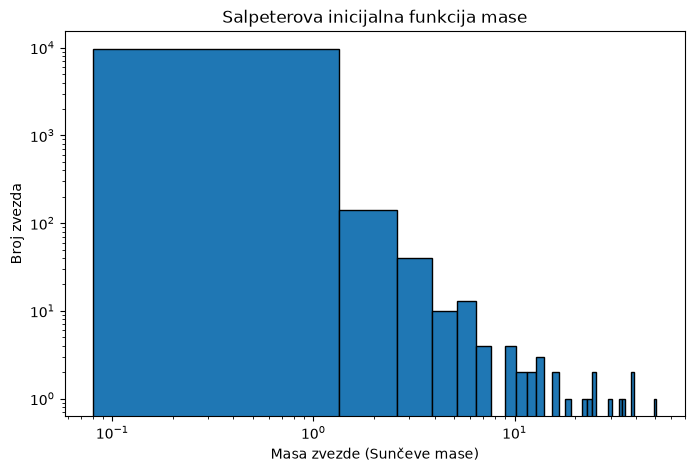

In [4]:
# Zadati parametri:
# Broj zvezda: N = 10000
# Minimalna masa: M_min = 0.08 M⊙
# Maksimalna masa: M_max = 200 M⊙
# Salpeterov indeks: α = 2.35
# Salpeterova funkcija: dN/dM ∝ M**-2.35

N = 10000
M_min = 0.08
M_max = 200
alpha = 2.35

#Generisanje 10000 zvezda

u = np.random.uniform(0, 1, N)
# formula
mase = (M_min**(1-alpha) + u * (M_max**(1-alpha) - M_min**(1-alpha)))**(1/(1-alpha))

print("Broj simuliranih zvezda:", len(mase))
print("Najmanja masa:", np.min(mase))
print("Najveća masa:", np.max(mase))
print("Prosečna masa:", np.mean(mase))

# Histogram za raspodelu masa zvezda


plt.figure(figsize=(8,5))
plt.hist(mase, bins=40, edgecolor='black')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Masa zvezde (Sunčeve mase)')
plt.ylabel('Broj zvezda')
plt.title('Salpeterova inicijalna funkcija mase')
plt.show()



Grafik pokazuje da najviše ima zvezda male mase (mase između 0 i 1 mase Sunca), dok je broj zvezda za veće mase manji, što je i očekivana raspodela u skladu sa Salpeterovom funkcijom.
Širine pravougaonika predstavljaju intervale masa, a njihova visina prikazuje broj zvezda po svakom intervalu.

##### <font color="green">2. Odrediti luminoznost i apsolutnu magnitudu svih zvezda.</font>

Broj zvezda: 10000
Luminoznost prve zvezde: 0.04491135556533356
Apsolutna magnituda prve zvezde: 8.109109590930416
Najmanja luminoznost: 0.00014482471428969995
Najveca luminoznost: 928329.141928436
Najmanja apsolutna magnituda: -10.179254959888693
Najveca apsolutna magnituda: 14.337893299011313


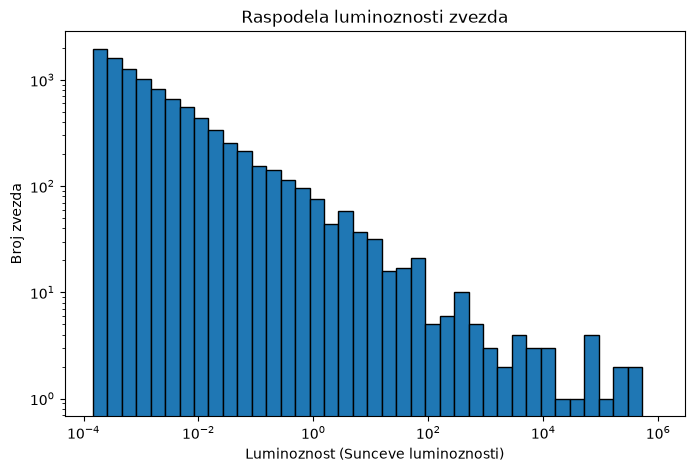

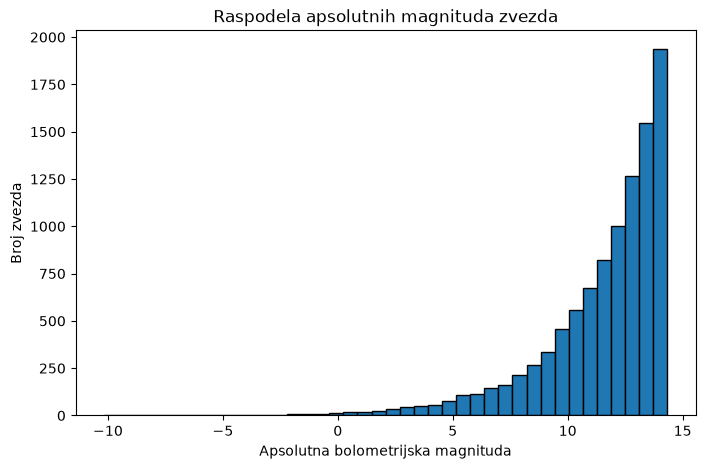

In [6]:
# Luminoznost: L ∝ M **3.5

luminoznosti = mase**3.5

# Izracunavanje apsolutne bolometrijske magnitude
# M = M⊙ - 2.5log(L/L⊙)
# M⊙_bol = 4.74
# M_bol = 4.74 - 2.5log(L)


apsolutne_magnitude = 4.74 - 2.5 * np.log10(luminoznosti)


print("Broj zvezda:", len(mase))
print("Luminoznost prve zvezde:", luminoznosti[0])
print("Apsolutna magnituda prve zvezde:", apsolutne_magnitude[0])
print("Najmanja luminoznost:", np.min(luminoznosti))
print("Najveca luminoznost:", np.max(luminoznosti))
print("Najmanja apsolutna magnituda:", np.min(apsolutne_magnitude))
print("Najveca apsolutna magnituda:", np.max(apsolutne_magnitude))


# Histogrm luminoznosti
plt.figure(figsize=(8,5))

bins = np.logspace(
    np.log10(np.min(luminoznosti)),
    np.log10(np.max(luminoznosti)),
    40
)

plt.hist(luminoznosti, bins=bins, edgecolor='black')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Luminoznost (Sunceve luminoznosti)')
plt.ylabel('Broj zvezda')
plt.title('Raspodela luminoznosti zvezda')
plt.show()


# Histogram apsolutnih mahnituda

plt.figure(figsize=(8,5))
plt.hist(apsolutne_magnitude, bins=40, edgecolor='black')
plt.xlabel('Apsolutna bolometrijska magnituda')
plt.ylabel('Broj zvezda')
plt.title('Raspodela apsolutnih magnituda zvezda')
plt.show()



1. Kod histograma luminoznosti vidi se da najveći brok zvezda ima malu luminoznost, dok je broj zvezda sa velikom lumonoznošću jako mali. Mali broj veoma sjajnih zvezda odgovara onom malom broju zvezda velikih masa. Dakle zvezde velikih masa imaju i veliku lumonoznost, što je i očekivano.

2. Kod histograma apsolutnih magnituda, najveći broj zvezda se nalazi na desnoj strani, te zvezde imaju velike pozitivne apsolutne magnitude, dok manji broj zvezda ima male ili negativne magnitude (levo), jer što je apsolutna magnituda manja, to je zvezda sjanija, a veoma masivnih i sjajnih zvezda ima najmanje.

##### <font color="green">3. Pretpostavljajući da je maksimalna udaljenost zvezda 10kpc, i da su uniformno raspoređene u sferi, semplovati njihove udaljenosti i odrediti prividne magnitude i prikazati histogram (m).</font>

Najmanja udaljenost: 0.3856560228304365 kpc
Najveca udaljenost: 9.999571596664067 kpc
Prosecna udaljenost: 7.504804686993072 kpc
Broj zvezda: 10000
Najmanja prividna magnituda: 3.749661902693317
Najveca prividna magnituda: 29.319379556884318
Prosecna prividna magnituda: 25.77968499943792


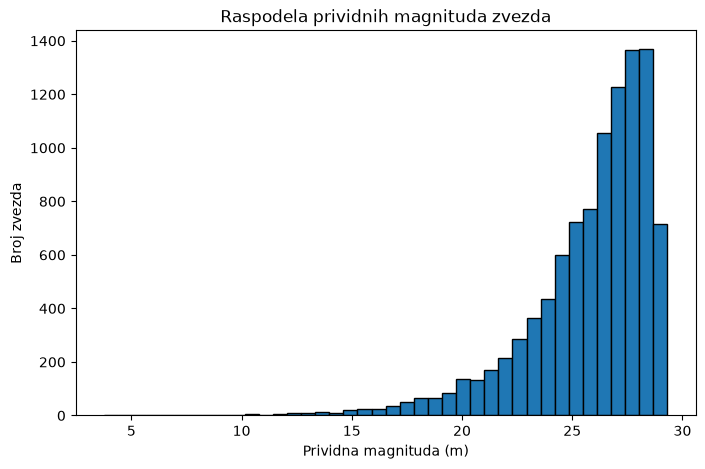

In [ ]:

# Maksimalna udaljenost u kpc
R_max = 10

# Generisanje slucajnih brojeva
u = np.random.uniform(0, 1, N)

# generisanje udaljenosti zvezda
udaljenosti = R_max * u**(1/3)


print("Najmanja udaljenost:", np.min(udaljenosti), "kpc")
print("Najveca udaljenost:", np.max(udaljenosti), "kpc")
print("Prosecna udaljenost:", np.mean(udaljenosti), "kpc")


# Izračunavanje prividnih magnituda
prividne_magnitude = apsolutne_magnitude + 5*np.log10(udaljenosti) + 10

print("Broj zvezda:", len(prividne_magnitude))
print("Najmanja prividna magnituda:",
      np.min(prividne_magnitude))

print("Najveca prividna magnituda:",
      np.max(prividne_magnitude))

print("Prosecna prividna magnituda:",
      np.mean(prividne_magnitude))

# Histogram
plt.figure(figsize=(8,5))
plt.hist(prividne_magnitude, bins=40, edgecolor='black')
plt.xlabel('Prividna magnituda (m)')
plt.ylabel('Broj zvezda')
plt.title('Raspodela prividnih magnituda zvezda')
plt.show()



Histogram je očekivanog oblika (asimetričnog, sa naglim porastom broja zvezda sa malim prividnim magnitudama), jer na prividnu magnitudu utiču i luminoznost zvezde i njena udaljenost od posmatrača. Zvezde koje su bliže i imaju veću luminoznost imaju manje prividne magnitude, odnosno izgledaju sjajnije. Zbog Salpertove raspodele, najviše je zvezda slabijih prividnih magnituda, što ovaj grafik i pokazuje. (Napomena: veći broj priidne magnitude na grafiku označava manji sjaj zvezde)


##### <font color="green">4. Analizirati kako se menja broj detektovanih zvezda u zavisnosti od udaljenosti za maksimalnu prividnu magnitudu koja može biti detektovana od 15, 18 i 22.</font>

Granicna magnituda: 15
Broj detektovanih zvezda: 86
Granicna magnituda: 18
Broj detektovanih zvezda: 242
Granicna magnituda: 22
Broj detektovanih zvezda: 976


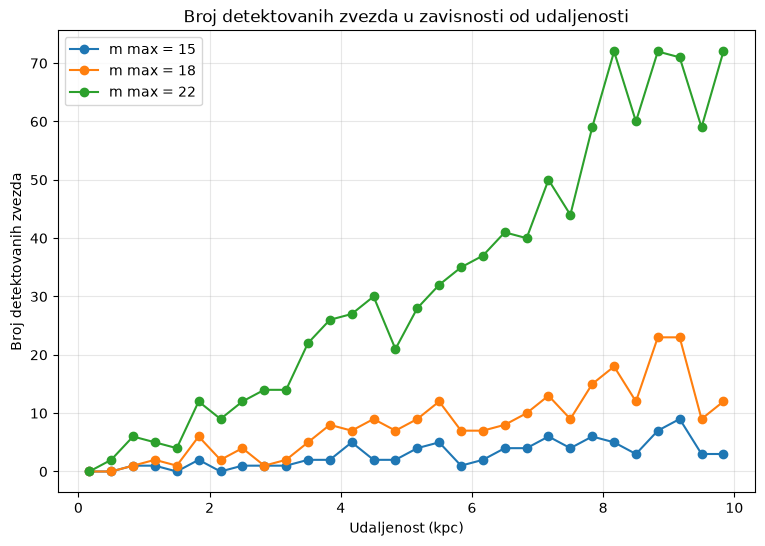

In [12]:
#3 slučaja:
# m_max = 15 detektuju se samo relativno sjajne zvezde
# m_max = 18 detektuje se veći broj zvezda
# m_max = 22 detektuju se i veoma slabe zvezde


# Granične prividne magnitude
granice = [15, 18, 22]


#Brojenje detektovanih zvezda za svaku granicnu magnitudu
for granica in granice:

    detektovane = prividne_magnitude <= granica

    broj = np.sum(detektovane)

    print("Granicna magnituda:", granica)
    print("Broj detektovanih zvezda:", broj)



# Podela udaljenosti na 30 intervala
bins = np.linspace(0, 10, 31)
# Centri intervala
centri = (bins[:-1] + bins[1:]) / 2

plt.figure(figsize=(9,6))

for granica in granice:

    # Uslov za detekciju
    detektovane = prividne_magnitude <= granica

    # Udaljenosti samo detektovanih zvezda
    r_det = udaljenosti[detektovane]

    # Broj zvezda u svakom intervalu udaljenosti
    broj_po_udaljenosti, _ = np.histogram(r_det, bins=bins)

    # Crtanje
    plt.plot(centri, broj_po_udaljenosti,
             marker='o',
             label=f'm max = {granica}')

plt.xlabel('Udaljenost (kpc)')
plt.ylabel('Broj detektovanih zvezda')
plt.title('Broj detektovanih zvezda u zavisnosti od udaljenosti')
plt.legend()
plt.grid(alpha=0.3)
plt.show()




Plava linija – broj zvezda koje možemo detektovati ako je granična magnituda 15.

Narandžasta linija – broj zvezda koje možemo detektovati ako je granična magnituda 18.

Zelena linija– broj zvezda koje možemo detektovati ako je granična magnituda 22.

Uočava se da se sa povećanjem granične magnitude povećava i broj detektovanih zvezda. Za graničnu magnitudu 15 detektuje se najmanji broj zvezda, dok se za graničnu magnitudu 22 detektuje najveći broj zvezda.
Takođe, primećuje se da broj detektovanih zvezda uglavnom raste sa udaljenošću (ovaj porast je ograničen mogućnostima detekcije, pošto udaljene zvezde imaju manju prividnu sjajnost).
Oscilacije koje se javljaju na grafikonu posledica su slučajne raspodele simuliranih zvezda i konačnog broja objekata u svakom intervalu udaljenosti.
Napomena: broj zvezda po intervalu udaljenosti raste i zbog geometrije sfere.



##### <font color="green">5. Prikazati grafike zavisnosti apsolutne magnitude od udaljenosti i označiti različitim simbolima detektovane i nedektovane zvezde, za sve tri granične magnitude. (Malmkvistova neobjektivnost)</font>

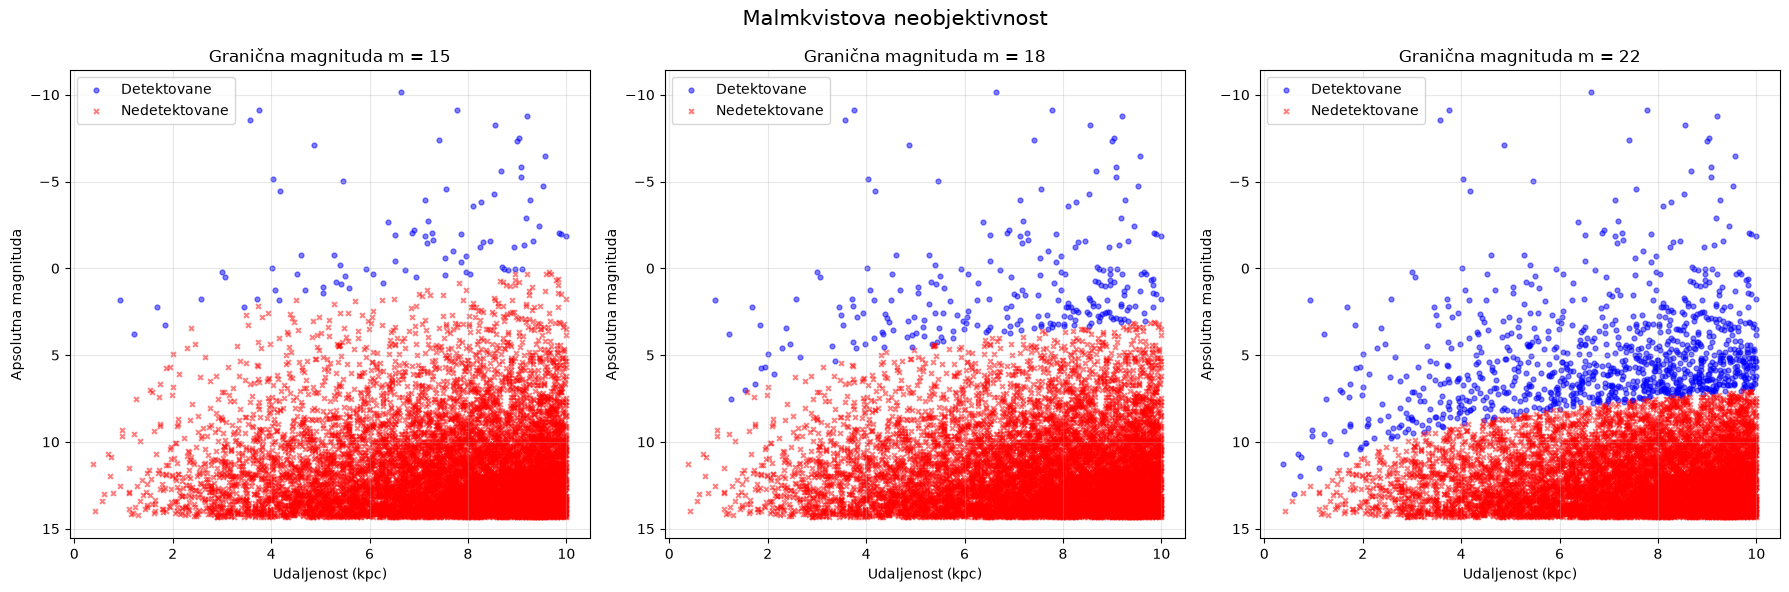

In [14]:
# Granične prividne magnitude
granice = [15, 18, 22]

# Tri grafikona
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, granica in zip(axes, granice):

    # Određivanje detektovanih zvezda
    detektovane = prividne_magnitude <= granica

    # Određivanje nedetektovanih zvezda
    nedetektovane = prividne_magnitude > granica

    # Detektovane zvezde
    ax.scatter(
        udaljenosti[detektovane],
        apsolutne_magnitude[detektovane],
        color='blue',
        marker='o',
        s=12,
        alpha=0.5,
        label='Detektovane'
    )

    #Nedetektovane zvezde
    ax.scatter(
        udaljenosti[nedetektovane],
        apsolutne_magnitude[nedetektovane],
        color='red',
        marker='x',
        s=12,
        alpha=0.5,
        label='Nedetektovane'
    )

    ax.set_xlabel('Udaljenost (kpc)')
    ax.set_ylabel('Apsolutna magnituda')
    ax.set_title(f'Granična magnituda m = {granica}')
    # sjanije zvezde se prikazuju na vrhu
    ax.invert_yaxis()
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Malmkvistova neobjektivnost', fontsize=15)
plt.tight_layout()
plt.show()


Očigledno je da je broj nedetektovanih zvezda daleko veći nego broj detektovanih, za sve 3 vrednosti graničnih magnituda, što je očekivano. Vidi  se da na manjim udaljenostima možemo detektovati zvezde različitih apsolutnih magnituda, dok se sa povećanjem udaljenosti smanjuje mogućnost detekcije zvezda manjeg sjaja. Na velikim udaljenostima uglavnom ostaju detektovane zvezde velike luminoznosti, odnosno manje apsolutne magnitude.

Ovaj efekat nastaje zbog ograničene granične prividne magnitude instrumenta.

Povećanjem granične prividne magnitude sa 15 na 18, pa na 22, povećava se broj detektovanih zvezda i smanjuje uticaj selekcije prema sjaju, jer instrument može da registruje i slabije sjajne objekte.